In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [2]:
import pandas as pd
print("\nLoading Dataset..")
dataset = pd.read_csv("spam.csv", encoding="latin-1")
print("Dataset Loaded Successfully")


Loading Dataset..
Dataset Loaded Successfully


In [3]:
print("\nDataset Information")
dataset.info()
print("\nDataet Shape")
print(dataset.shape)


Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Category    5572 non-null   object
 1   Message     5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Dataet Shape
(5572, 5)


In [4]:
print("\nMissing Values")
print(dataset.isnull().sum())


Missing Values
Category         0
Message          0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


In [7]:
print("\nEmail category count")
print(dataset["Category"].value_counts())


Email category count
Category
ham     4825
spam     747
Name: count, dtype: int64


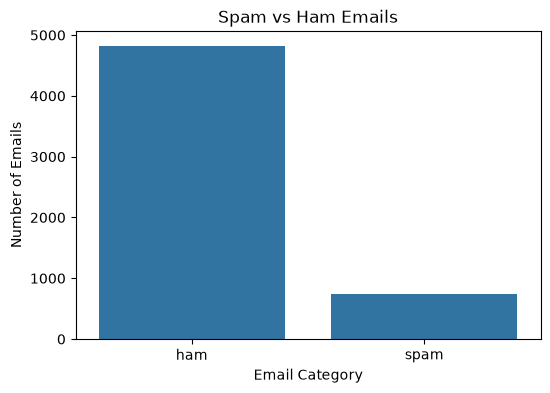

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(x="Category",data=dataset)
plt.title("Spam vs Ham Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")
plt.show()

In [11]:
x=dataset["Message"]
y=dataset["Category"]

In [12]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)
print("\nTraining Samples:",len(x_train))
print("Testing Samples:",len(x_test))


Training Samples: 4457
Testing Samples: 1115


In [13]:
print("\nConverting Text into numerical features...")
cv=CountVectorizer()
x_train=cv.fit_transform(x_train)
x_test=cv.transform(x_test)
print("conversion completed")
print("Training data shape:",x_train.shape)
print("Training data shape:",x_train.shape)
print("Testing data shape:",x_test.shape)



Converting Text into numerical features...
conversion completed
Training data shape: (4457, 7691)
Training data shape: (4457, 7691)
Testing data shape: (1115, 7691)


In [14]:
print("\nTraining SVM model....")
classifier=SVC(kernel="linear")
classifier.fit(x_train,y_train)
print("Model Training completed")


Training SVM model....
Model Training completed


In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

model = MultinomialNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("MODEL ACCURACY")
print("Accuracy = {:.2f}%".format(accuracy * 100))

MODEL ACCURACY
Accuracy = 96.23%



Confusion Matrix
[[965   0]
 [ 42 108]]


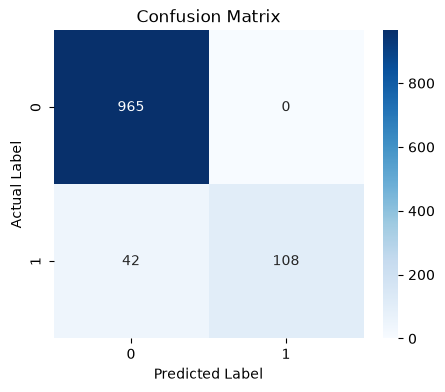

In [26]:
cm=confusion_matrix(y_test,y_pred)
print("\nConfusion Matrix")
print(cm)
plt.figure(figsize=(5,4))
sns.heatmap(cm,annot=True,
            fmt='d',
            cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [27]:
print("\nClassification Report")
print(classification_report(y_test,y_pred))


Classification Report
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       965
        spam       1.00      0.72      0.84       150

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



In [1]:
print("Sample Predictions")

sample_messages = [
     "Congratulations! you have won a free iphone. Click here to claim.",
     "URGENT! Your bank account has been suspended. Verify immediately.",
     "Happy Birthday! Have a wonderful day.",
     "You have won Rs.50000 cash prize. Call now."
]

sample_data = cv.transform(sample_messages)
predictions = classifier.predict(sample_data)

for message, prediction in zip(sample_messages, predictions):
    print("\nMessage:")
    print(message)
    print("Prediction:", prediction)

Sample Predictions


NameError: name 'cv' is not defined